In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from PIL import Image
import matplotlib.pyplot as plt 
from matplotlib.pyplot import figure
import numpy as np 
from PIL import ImageFilter
import os
import math
from tqdm import tqdm

In [ ]:
def divide_image_in_patches_reduced_dataset_size(image_path, patch_dim = 256):
    img = Image.open(image_path)
    img_array = np.array(img)
    n_max_w_patches = 256 * math.ceil(img_array.shape[0] / 256)
    n_max_h_patches = 256 * math.ceil(img_array.shape[1] / 256)

    tmp = np.zeros([n_max_w_patches, n_max_h_patches,img_array.shape[2]], dtype=np.uint8)
    tmp[:img_array.shape[0],:img_array.shape[1],:img_array.shape[2]] = img_array
    img_array = tmp

    patches_array = []

    '''print(img_array.shape)
    print("width:",n_max_w_patches)
    print("heigh:",n_max_h_patches)
    print("width:",np.arange(0,n_max_w_patches+patch_dim,patch_dim))
    print("heigh:",np.arange(0,n_max_h_patches+patch_dim,patch_dim))'''
    
    for i in np.arange(0,n_max_w_patches+patch_dim,128):
        for j in np.arange(0,n_max_h_patches+patch_dim,128):
            if img_array[i:i+patch_dim,j:j+patch_dim,:].shape == (patch_dim,patch_dim,img_array.shape[2]):
                patches_array.append( img_array[i:i+patch_dim,j:j+patch_dim,:] )
            
    return np.array(patches_array)

(315, 256, 256, 3)


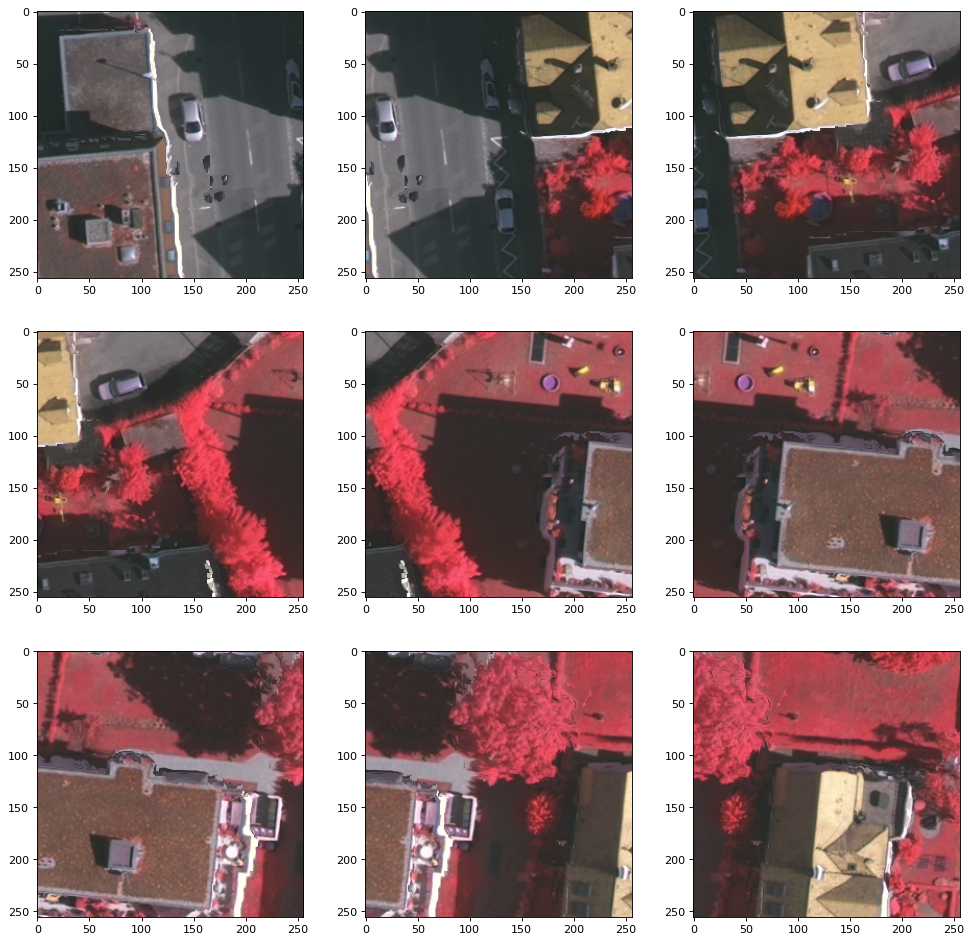

In [ ]:
patches_array = divide_image_in_patches_reduced_dataset_size("/content/drive/MyDrive/Colab Notebooks/semantic_labelling/Dataset/Vaihingen/ISPRS_semantic_labeling_Vaihingen/top/top_mosaic_09cm_area1.tif")
print(patches_array.shape)

figure(figsize=(15, 15), dpi=80)

for i in np.arange(1,10):
    plt.subplot(3,3,i)
    plt.imshow(patches_array[i])

plt.show()

In [ ]:
def check_shape(patches_array):
    reference_shape = patches_array[0].shape
    for item in np.arange(0,patches_array.shape[0]):
        if not patches_array[item].shape == reference_shape:
            print("item shape: "+str(patches_array[item].shape))
            #print(patches_array[item])
            print("reference shape: "+str(reference_shape))
            print("error")
            break

check_shape(patches_array)

In [ ]:
patches_array_1 = divide_image_in_patches_reduced_dataset_size("/content/drive/MyDrive/Colab Notebooks/semantic_labelling/Dataset/Vaihingen/ISPRS_semantic_labeling_Vaihingen/top/top_mosaic_09cm_area1.tif")
print(patches_array_1.shape)

patches_array_2 = divide_image_in_patches_reduced_dataset_size("/content/drive/MyDrive/Colab Notebooks/semantic_labelling/Dataset/Vaihingen/ISPRS_semantic_labeling_Vaihingen/top/top_mosaic_09cm_area2.tif")
print(patches_array_2.shape)

(315, 256, 256, 3)
(399, 256, 256, 3)


In [ ]:
conc = np.concatenate((patches_array_1,patches_array_2),axis=0)
conc.shape

(714, 256, 256, 3)

## Define and create the destination folders

In [ ]:
try:
    os.mkdir("/content/drive/MyDrive/Colab Notebooks/semantic_labelling/Dataset/ISPRS_semantic_labeling_Vaihingen_processed")
    print("ISPRS_semantic_labeling_Vaihingen_processed created")
except:
    print("ISPRS_semantic_labeling_Vaihingen_processed folder already exists")

try:
    os.mkdir("/content/drive/MyDrive/Colab Notebooks/semantic_labelling/Dataset/ISPRS_semantic_labeling_Vaihingen_processed/top")
    print("top created")
except:
    print("top folder already exists")

try:
    os.mkdir("/content/drive/MyDrive/Colab Notebooks/semantic_labelling/Dataset/ISPRS_semantic_labeling_Vaihingen_processed/gts_for_participants")
except:
    print("gts_for_participants folder already exists")

ISPRS_semantic_labeling_Vaihingen_processed folder already exists
top folder already exists
gts_for_participants folder already exists


### preprocessing the top images

In [ ]:
root_dir = "/content/drive/MyDrive/Colab Notebooks/semantic_labelling/Dataset/Vaihingen/ISPRS_semantic_labeling_Vaihingen/top/"
dest_dir = "/content/drive/MyDrive/Colab Notebooks/semantic_labelling/Dataset/ISPRS_semantic_labeling_Vaihingen_processed/top/"

for root, dirs, files in os.walk(root_dir, topdown=False):
    for name in files:
        #print(os.path.join(root, name))
        #print(name.replace(".tif","_patch_{}.tif".format(10)))
        file_number = name[name.find("area")+len("area"):].replace(".tif","")
        patches_array = divide_image_in_patches_reduced_dataset_size(os.path.join(root, name))
        for i in tqdm(np.arange(patches_array.shape[0])):
            im = Image.fromarray(patches_array[i,:,:,:])
            #print(dest_dir+name.replace(".tif","")+"_patch"+str(i)+".tif")
            im.save(dest_dir+name.replace(".tif","")+"_patch_"+str(i)+".tif")
        print("completed area "+file_number)

In [ ]:
name_list = []
for root, dirs, files in os.walk(dest_dir, topdown=False):
    print(os.path.join(root, name))


/content/drive/MyDrive/Colab Notebooks/semantic_labelling/Dataset/ISPRS_semantic_labeling_Vaihingen_processed/top/top_mosaic_09cm_area35.tif


## preprocessing the gts images

In [ ]:
root_dir = "/content/drive/MyDrive/Colab Notebooks/semantic_labelling/Dataset/Vaihingen/ISPRS_semantic_labeling_Vaihingen/gts_for_participants/"
dest_dir = "/content/drive/MyDrive/Colab Notebooks/semantic_labelling/Dataset/ISPRS_semantic_labeling_Vaihingen_processed/gts_for_participants/"

for root, dirs, files in os.walk(root_dir, topdown=False):
    for name in files:
        #print(os.path.join(root, name))
        #print(name.replace(".tif","_patch_{}.tif".format(10)))
        file_number = name[name.find("area")+len("area"):].replace(".tif","")
        patches_array = divide_image_in_patches_reduced_dataset_size(os.path.join(root, name))
        for i in tqdm(np.arange(patches_array.shape[0])):
            im = Image.fromarray(patches_array[i,:,:,:])
            #print(dest_dir+name.replace(".tif","")+"_patch"+str(i)+".tif")
            im.save(dest_dir+name.replace(".tif","")+"_patch_"+str(i)+".tif")
        print("completed area "+file_number)

100%|██████████| 315/315 [00:03<00:00, 87.60it/s]


completed area 1


100%|██████████| 225/225 [00:02<00:00, 90.35it/s]


completed area 37


100%|██████████| 209/209 [00:02<00:00, 83.71it/s]


...

completed area 32


100%|██████████| 315/315 [00:03<00:00, 90.13it/s]


completed area 28


100%|██████████| 299/299 [00:03<00:00, 92.38it/s]

completed area 26
